In [1]:
%load_ext autoreload
%autoreload 2

# Modelos

Seguimos desde el notebook de datos. Ahi vimos que el bloque de no-detecciones y los colores WISE no aportan, y que el periodo hay que pasarlo a log porque si no aplasta al resto.

Acá partimos train / val / test **antes** de imputar y escalar. Despues entrenamos un autoencoder, un GMM en el cuello de botella, y una pasada de MCDSVDD.

In [2]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# jupyter a veces parte en notebooks/ y a veces en la raiz
aqui = Path.cwd().resolve()
raiz = aqui if (aqui / "src").exists() else aqui.parent
if str(raiz / "src") not in sys.path:
    sys.path.insert(0, str(raiz / "src"))

from ic_project.modelos import asignar_mcdsvdd, entrenar_autoencoder, entrenar_mcdsvdd, latente
from ic_project.preprocesamiento import preparar_conjuntos

colores = {
    "CEP": "steelblue",
    "DSCT": "chocolate",
    "EB": "mediumseagreen",
    "LPV": "indianred",
    "RRL": "magenta",
}

In [3]:
ruta_datos = raiz / "data" / "raw"

df_features = pd.read_parquet(ruta_datos / "features.parquet")
df_oids = pd.read_parquet(ruta_datos / "oids.parquet")

print("features", df_features.shape)
print("oids    ", df_oids.shape)

X = df_features.drop(columns="oid")
oids = df_features["oid"].reset_index(drop=True)
labels = df_features[["oid"]].merge(df_oids, on="oid", how="left")["alerceclass"].reset_index(drop=True)

mask = labels.notna()
X = X.loc[mask].reset_index(drop=True)
oids = oids.loc[mask].reset_index(drop=True)
labels = labels.loc[mask].reset_index(drop=True)

print(labels.value_counts())

features (8419, 179)
oids     (9829, 2)
alerceclass
EB      2689
RRL     2652
LPV     1374
CEP     1172
DSCT     532
Name: count, dtype: int64


### Particion

70% train, 15% val, 15% test, estratificado por clase. La mediana, el recorte y la escala se calculan solo con train. Si se calculan con todo el conjunto, el test se filtra al modelo.

La escala es z-score: a cada feature se le resta la media y se divide por la desviacion estandar de train. Antes dividiamos por el IQR, pero las features de cola pesada (`Harmonics_mag_*`, `delta_period_*`) quedaban con valores de cientos y se llevaban casi todo el error del autoencoder. Con z-score todas pesan lo mismo.

In [4]:
# solo_periodo_color=False: aca entran las 158 features, no solo las 7 de periodo y color
conjuntos, prep, descartadas = preparar_conjuntos(X, labels, oids, solo_periodo_color=False)

print("descartadas:", len(descartadas))
print(
    "train / val / test:",
    len(conjuntos["y_train"]),
    len(conjuntos["y_val"]),
    len(conjuntos["y_test"]),
)
print("features que entran al modelo:", conjuntos["x_train"].shape[1])
print(conjuntos["y_train"].value_counts())

descartadas: 20
train / val / test: 5893 1263 1263
features que entran al modelo: 158
alerceclass
EB      1883
RRL     1856
LPV      962
CEP      820
DSCT     372
Name: count, dtype: int64


### Autoencoder

Comprime las features a 8 numeros y trata de reconstruirlas. Esos 8 son el cuello de botella. Con 2 se pierde harto, asi que el grafico de mas abajo es un UMAP del test, igual que en el notebook de datos. El UMAP es solo para mirar, no entra al GMM.

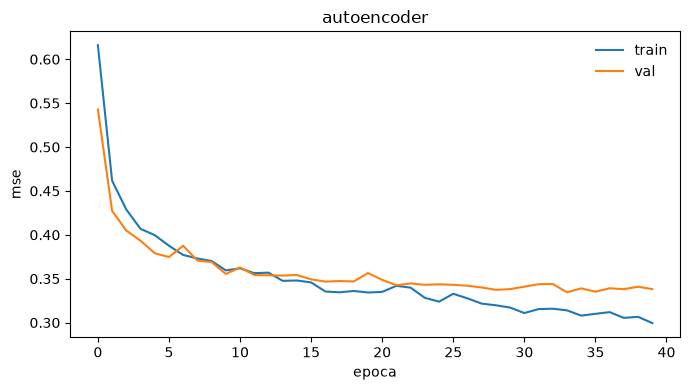

epocas corridas: 40
mejor mse val: 0.3345


In [5]:
ae, hist = entrenar_autoencoder(
    conjuntos["x_train"],
    conjuntos["x_val"],
    z_dim=8,
    n_epocas=40,
    semilla=42,
)

plt.figure(figsize=(7, 4))
plt.plot(hist.train, label="train")
plt.plot(hist.val, label="val")
plt.xlabel("epoca")
plt.ylabel("mse")
plt.legend(frameon=False)
plt.title("autoencoder")
plt.tight_layout()
plt.show()

print("epocas corridas:", len(hist.val))
print("mejor mse val:", round(min(hist.val), 4))

C:\Users\fonse\Desktop\Universidad\Inteligencia\Proyecto\Git-proyecto\alerce-meeting2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\fonse\Desktop\Universidad\Inteligencia\Proyecto\Git-proyecto\alerce-meeting2\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


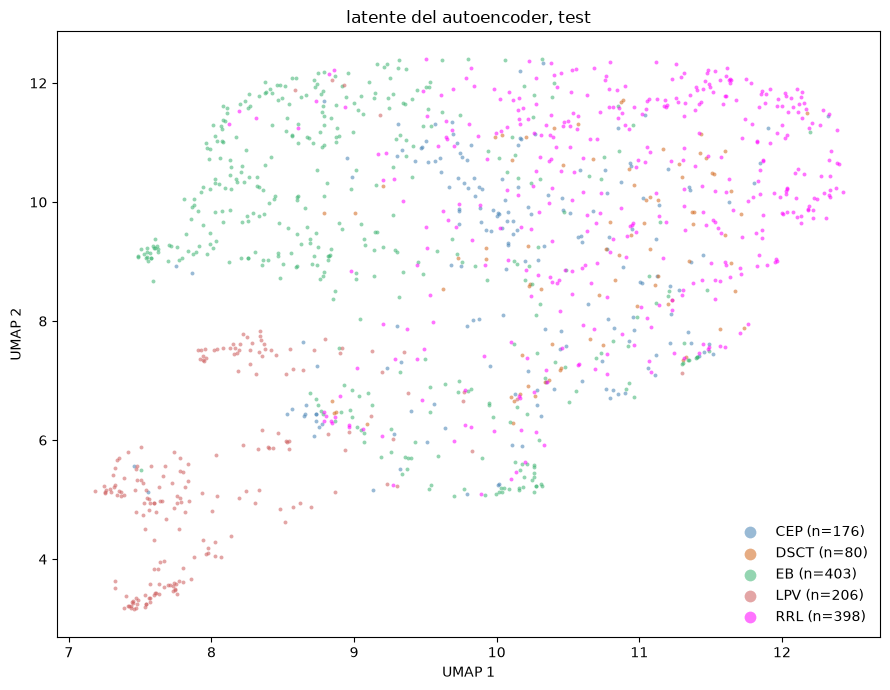

In [6]:
import umap

z_train = latente(ae, conjuntos["x_train"])
z_test = latente(ae, conjuntos["x_test"])

# UMAP solo del test, para dibujar
emb = umap.UMAP(n_neighbors=50, min_dist=0.1, n_components=2, random_state=42).fit_transform(z_test)

clases_test = conjuntos["y_test"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 7))
for clase, color in colores.items():
    m = clases_test == clase
    ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.55, c=color, label=f"{clase} (n={m.sum()})", linewidths=0)

ax.legend(markerscale=3, frameon=False)
ax.set_title("latente del autoencoder, test")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.tight_layout()
plt.show()

El MSE de validacion queda en 0.33. Como cada feature tiene varianza 1, eso es un tercio de la varianza sin reconstruir usando solo 8 numeros.

LPV queda aparte. EB y RRL se van a lados distintos pero se tocan, y CEP y DSCT quedan repartidas entre las dos. Un clustering que no ve la etiqueta puede recuperar LPV, pero no tiene de donde sacar las 5 clases.

### GMM

Mezcla de gaussianas con 5 componentes, ajustada **solo** con el latente de train. Las metricas son del test.

Silhouette mas alto = grupos mas separados. Davies-Bouldin mas bajo = mejor. Esas dos las calculamos con los clusters del GMM y tambien con las clases reales (no miden lo mismo). ARI y NMI comparan clusters contra clase: 0 es azar, 1 es que coinciden.

In [7]:
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture


def medir(z, pred, real):
    print("silhouette grupos ", round(silhouette_score(z, pred), 3))
    print("silhouette clases ", round(silhouette_score(z, real), 3))
    print("davies-bouldin grupos", round(davies_bouldin_score(z, pred), 3))
    print("davies-bouldin clases", round(davies_bouldin_score(z, real), 3))
    print("ARI", round(adjusted_rand_score(real, pred), 3))
    print("NMI", round(normalized_mutual_info_score(real, pred), 3))


gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42, n_init=5)
gmm.fit(z_train)
pred_gmm = gmm.predict(z_test)

print("GMM en test")
medir(z_test, pred_gmm, clases_test)
print()
display(pd.crosstab(clases_test, pred_gmm, rownames=["clase"], colnames=["cluster"]))

GMM en test
silhouette grupos  0.079
silhouette clases  -0.016
davies-bouldin grupos 2.726
davies-bouldin clases 3.617
ARI 0.201
NMI 0.263



cluster,0,1,2,3,4
clase,,,,,
CEP,3,78,3,40,52
DSCT,0,15,0,17,48
EB,0,161,24,77,141
LPV,71,11,102,21,1
RRL,0,49,0,43,306


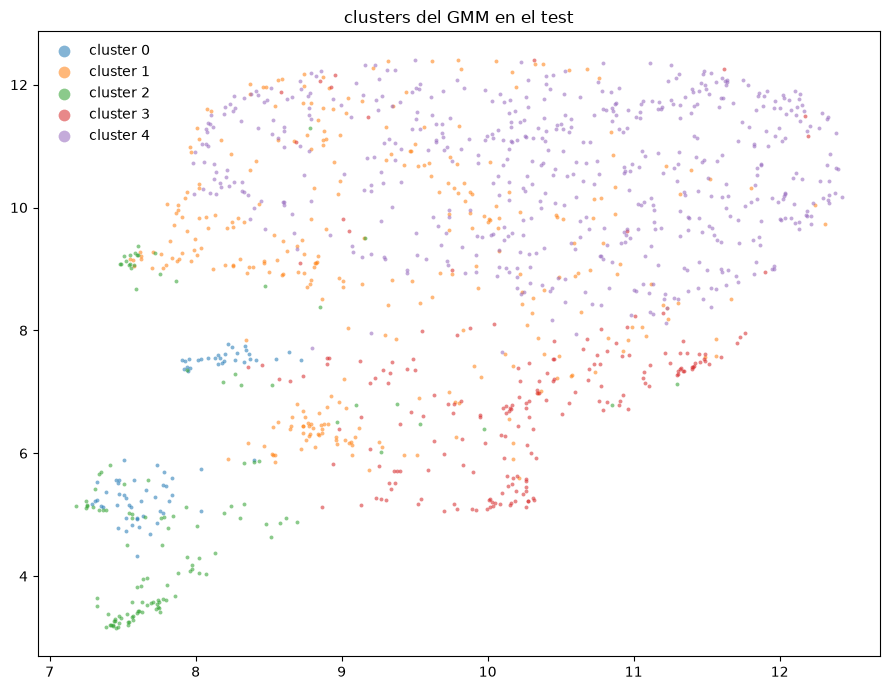

In [8]:
# mismos ejes que el UMAP de arriba, ahora pintado por cluster
fig, ax = plt.subplots(figsize=(9, 7))
for k in np.unique(pred_gmm):
    m = pred_gmm == k
    ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.55, label=f"cluster {k}", linewidths=0)
ax.legend(markerscale=3, frameon=False)
ax.set_title("clusters del GMM en el test")
plt.tight_layout()
plt.show()

El GMM no ve la clase. En la tabla se nota que LPV es la unica que recupera: 173 de 206 caen en dos componentes donde casi no hay otra cosa. El resto va mezclado: un componente junta a la mayoria de RRL con harto EB y DSCT, y CEP queda repartida. El ARI es 0.20, o sea recupera poco de las etiquetas. Calza con el UMAP de arriba.

### MCDSVDD

Este si usa la clase. Parte del encoder que ya entrenamos, calcula un centro por clase y acerca cada objeto al centro de la suya. En test lo asignamos al centro mas cercano.

DSCT tiene harto menos objetos que EB y RRL, y la perdida promedia todos los objetos por igual, asi que las clases chicas pesan poco. Para compensarlo, al entrenar repetimos objetos de cada clase hasta igualar a la mas grande. Es solo en train: val y test quedan con sus proporciones reales.

objetos por clase en train: {'CEP': 820, 'DSCT': 372, 'EB': 1883, 'LPV': 962, 'RRL': 1856}
al entrenar: 1883 por clase, 9415 en total


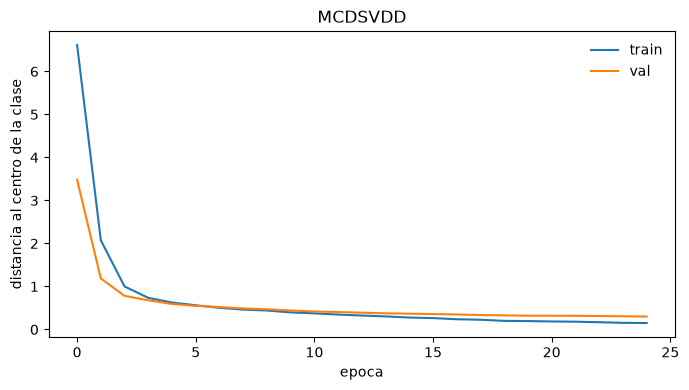

epocas: 25


In [9]:
clases = sorted(conjuntos["y_train"].unique())
mapa = {c: i for i, c in enumerate(clases)}

y_train_i = conjuntos["y_train"].map(mapa).to_numpy()
y_val_i = conjuntos["y_val"].map(mapa).to_numpy()

# sobremuestreo: cada clase entra tantas veces como la mas grande, repitiendo objetos de las chicas.
# es solo para entrenar; val y test quedan con sus proporciones reales
rng = np.random.default_rng(42)
por_clase = [np.flatnonzero(y_train_i == k) for k in range(len(clases))]
n_max = max(len(ix) for ix in por_clase)
balanceado = np.concatenate([rng.choice(ix, size=n_max, replace=len(ix) < n_max) for ix in por_clase])
print("objetos por clase en train:", dict(zip(clases, map(len, por_clase))))
print("al entrenar:", n_max, "por clase,", len(balanceado), "en total")

mcd, hist_mcd = entrenar_mcdsvdd(
    conjuntos["x_train"][balanceado],
    y_train_i[balanceado],
    conjuntos["x_val"],
    y_val_i,
    autoencoder=ae,
    z_dim=8,
    n_epocas=25,
    semilla=42,
)

plt.figure(figsize=(7, 4))
plt.plot(hist_mcd.train, label="train")
plt.plot(hist_mcd.val, label="val")
plt.xlabel("epoca")
plt.ylabel("distancia al centro de la clase")
plt.legend(frameon=False)
plt.title("MCDSVDD")
plt.tight_layout()
plt.show()

print("epocas:", len(hist_mcd.val))

C:\Users\fonse\Desktop\Universidad\Inteligencia\Proyecto\Git-proyecto\alerce-meeting2\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


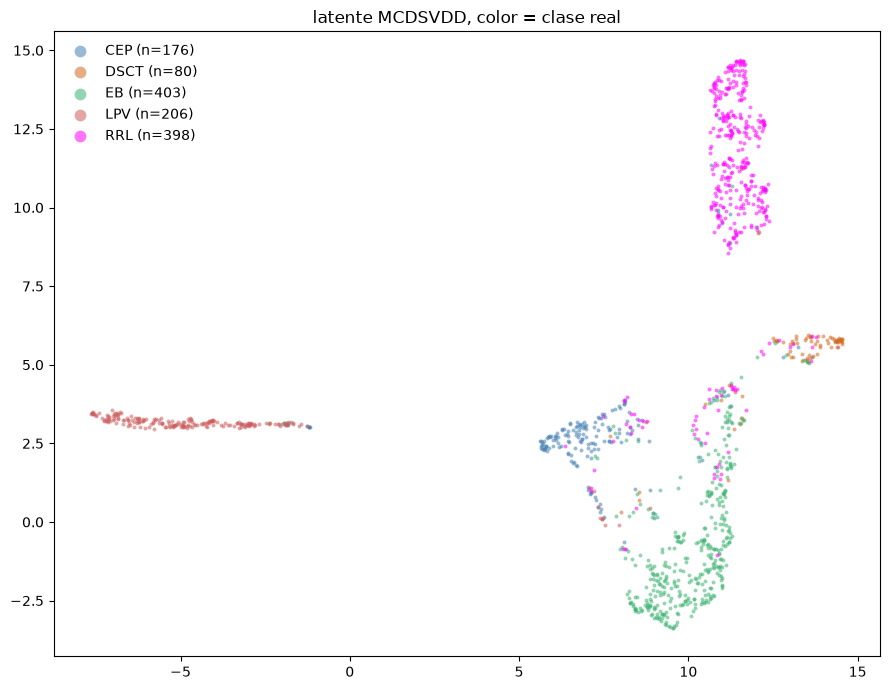

MCDSVDD en test
silhouette grupos  0.602
silhouette clases  0.495
davies-bouldin grupos 0.61
davies-bouldin clases 0.759
ARI 0.731
NMI 0.669



centro,CEP,DSCT,EB,LPV,RRL
clase,,,,,
CEP,148,3,10,5,10
DSCT,5,63,5,0,7
EB,16,10,364,3,10
LPV,5,1,6,193,1
RRL,30,14,14,0,340


In [10]:
z_mcd = latente(mcd, conjuntos["x_test"])
pred_i = asignar_mcdsvdd(mcd, conjuntos["x_test"])
pred_mcd = np.array(clases)[pred_i]

emb_mcd = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42).fit_transform(z_mcd)

fig, ax = plt.subplots(figsize=(9, 7))
for clase, color in colores.items():
    m = clases_test == clase
    ax.scatter(emb_mcd[m, 0], emb_mcd[m, 1], s=8, alpha=0.55, c=color, label=f"{clase} (n={m.sum()})", linewidths=0)
ax.legend(markerscale=3, frameon=False)
ax.set_title("latente MCDSVDD, color = clase real")
plt.tight_layout()
plt.show()

print("MCDSVDD en test")
medir(z_mcd, pred_mcd, clases_test)
print()
display(pd.crosstab(clases_test, pred_mcd, rownames=["clase"], colnames=["centro"]))

Mejora harto respecto al GMM (ARI 0.73 contra 0.20) porque ahora el modelo si vio la clase al entrenar. En la diagonal de la tabla estan los que caen en su propio centro, y las cinco clases quedan mayormente en el suyo.

El sobremuestreo se nota en DSCT: 63 de 80 caen en su centro, y sin balancear eran 26. Tambien sube el ARI, que sin balancear era 0.69. Lo que mas se confunde ahora es RRL, con 30 objetos que se van a CEP y 14 a DSCT.

### Que features importan

Random forest solo con train, con peso para las clases chicas. No lo usamos para filtrar el autoencoder, es para ver si el periodo queda arriba.

Los hiperparametros ya no van a mano: `RandomizedSearchCV` prueba 20 combinaciones al azar con validacion cruzada de 3 folds dentro de train. La metrica es F1 macro, para que DSCT pese lo mismo que EB y RRL. El val y el test no entran a la busqueda.

mejores hiperparametros: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 16}
f1 macro en validacion cruzada: 0.912
f1 macro en val: 0.923

Multiband_period_g_r    0.098860
Period_band_g           0.080993
Period_band_r           0.049998
g-r_mean_g_r            0.038102
g-r_max_corr_g_r        0.037000
GP_DRW_tau_r            0.035641
g-r_mean_corr_g_r       0.034271
g-r_max_g_r             0.029831
Autocor_length_r        0.029125
IAR_phi_r               0.026877
GP_DRW_tau_g            0.022821
IAR_phi_g               0.017307
dtype: float64


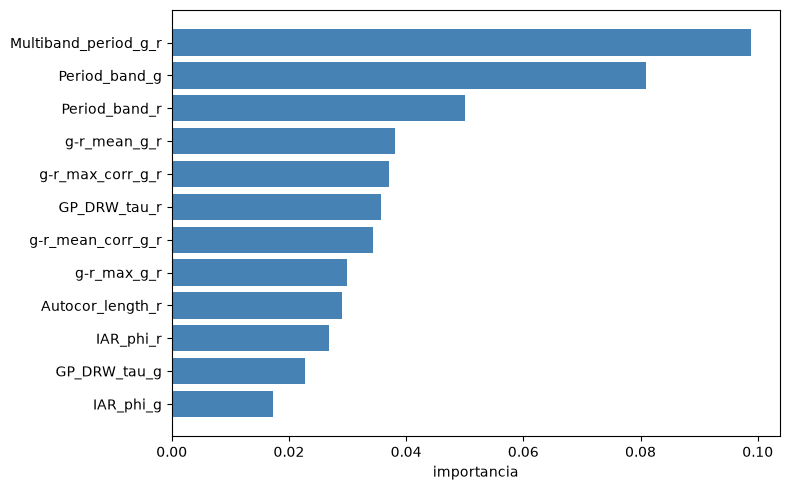

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# valores entre los que sortea la busqueda
espacio = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [8, 12, 16, 24, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.2],
}

busqueda = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_distributions=espacio,
    n_iter=20,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
)
# 20 combinaciones x 3 folds, se demora un par de minutos
busqueda.fit(conjuntos["x_train"], conjuntos["y_train"])

print("mejores hiperparametros:", busqueda.best_params_)
print("f1 macro en validacion cruzada:", round(busqueda.best_score_, 3))

# el mejor queda reentrenado con todo train
rf = busqueda.best_estimator_
pred_val = rf.predict(conjuntos["x_val"])
print("f1 macro en val:", round(f1_score(conjuntos["y_val"], pred_val, average="macro"), 3))
print()

imp = pd.Series(rf.feature_importances_, index=prep.columnas_).sort_values(ascending=False)
print(imp.head(12))

top = imp.head(12)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="steelblue")
plt.xlabel("importancia")
plt.tight_layout()
plt.show()

La busqueda termina casi donde estabamos a mano (200 arboles, profundidad 16), solo cambia el minimo de objetos por hoja. El ranking tampoco se mueve: las primeras son periodos (multibanda, banda g, banda r) y despues el color g-r. Era lo que esperabamos: las clases viven en escalas de tiempo distintas.

### Importancia contra datos faltantes

En el notebook de datos ordenamos las features por % de NaN. Aca cruzamos esa lista con la del random forest, para ver si lo que el modelo mas usa es justo lo que mas hubo que imputar.

El % de NaN se calcula igual que alla, sobre las 178 features crudas. La importancia existe solo para las 158 que entran al modelo: las 20 descartadas quedan sin valor.

In [12]:
# mismo calculo que en el notebook de datos
nan_pct = X.isna().mean() * 100

comp = pd.DataFrame({"pct_nan": nan_pct, "importancia": imp})
comp["puesto_nan"] = comp["pct_nan"].rank(ascending=False, method="min").astype(int)
comp["puesto_rf"] = comp["importancia"].rank(ascending=False, method="min").astype("Int64")
comp["descartada"] = comp.index.isin(descartadas)

redondeo = {"pct_nan": 1, "importancia": 4}

print("20 features con mas NaN")
display(comp.sort_values("pct_nan", ascending=False).head(20).round(redondeo))

print("15 features mas importantes del random forest")
display(comp.sort_values("importancia", ascending=False).head(15).round(redondeo))

20 features con mas NaN


,pct_nan,importancia,puesto_nan,puesto_rf,descartada
last_mjd_before_fid_g,41.6,NaN,1,<NA>,True
last_diffmaglim_before_fid_g,41.6,NaN,1,<NA>,True
median_diffmaglim_before_fid_g,41.6,NaN,1,<NA>,True
max_diffmaglim_before_fid_g,41.6,NaN,1,<NA>,True
dmag_non_det_fid_g,41.6,NaN,1,<NA>,True
dmag_first_det_fid_g,41.6,NaN,1,<NA>,True
dmag_non_det_fid_r,34.4,NaN,7,<NA>,True
dmag_first_det_fid_r,34.4,NaN,7,<NA>,True
max_diffmaglim_before_fid_r,34.4,NaN,7,<NA>,True
last_mjd_before_fid_r,34.4,NaN,7,<NA>,True


15 features mas importantes del random forest


,pct_nan,importancia,puesto_nan,puesto_rf,descartada
Multiband_period_g_r,0.0,0.0989,167,1,False
Period_band_g,6.1,0.0810,101,2,False
Period_band_r,8.6,0.0500,34,3,False
g-r_mean_g_r,10.7,0.0381,26,4,False
g-r_max_corr_g_r,12.6,0.0370,19,5,False
GP_DRW_tau_r,6.3,0.0356,67,6,False
g-r_mean_corr_g_r,12.6,0.0343,19,7,False
g-r_max_g_r,10.7,0.0298,26,8,False
Autocor_length_r,8.6,0.0291,34,9,False
IAR_phi_r,8.6,0.0269,34,10,False


en las 15 mas importantes y en las 15 con mas NaN: 5
   g-r_mean_g_r
   g-r_max_corr_g_r
   g-r_mean_corr_g_r
   g-r_max_g_r
   MHPS_ratio_r

correlacion de Spearman entre % NaN e importancia: 0.008
importancia que suman las 15 con mas NaN: 0.194

% de NaN por clase


alerceclass,CEP,DSCT,EB,LPV,RRL
g-r_mean_g_r,20.0,4.9,5.8,29.0,3.3
g-r_max_corr_g_r,21.4,8.5,7.9,32.0,4.4
g-r_mean_corr_g_r,21.4,8.5,7.9,32.0,4.4
g-r_max_g_r,20.0,4.9,5.8,29.0,3.3
MHPS_ratio_r,22.6,20.7,10.1,13.0,7.3


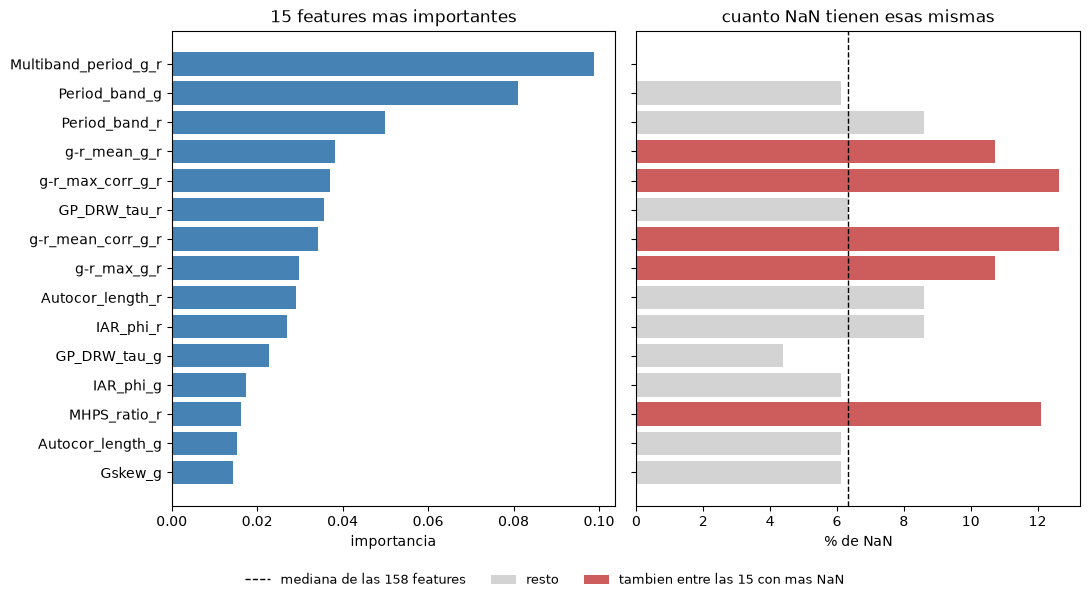

In [13]:
# de aca en adelante solo las 158 que vio el random forest
en_modelo = comp[~comp["descartada"]]
top_rf = en_modelo.sort_values("importancia", ascending=False).head(15)
top_nan = en_modelo.sort_values("pct_nan", ascending=False).head(15)
comunes = [c for c in top_rf.index if c in top_nan.index]

print("en las 15 mas importantes y en las 15 con mas NaN:", len(comunes))
for c in comunes:
    print("  ", c)
print()
print(
    "correlacion de Spearman entre % NaN e importancia:",
    round(en_modelo["pct_nan"].corr(en_modelo["importancia"], method="spearman"), 3),
)
print("importancia que suman las 15 con mas NaN:", round(top_nan["importancia"].sum(), 3))
print()

# el NaN de las que se repiten, separado por clase
print("% de NaN por clase")
display((X[comunes].isna().groupby(labels).mean() * 100).round(1).T)

filas = top_rf[::-1]
en_ambas = filas.index.isin(comunes)

fig, (ax_imp, ax_nan) = plt.subplots(1, 2, figsize=(11, 6), sharey=True)

ax_imp.barh(filas.index, filas["importancia"], color="steelblue")
ax_imp.set_xlabel("importancia")
ax_imp.set_title("15 features mas importantes")

ax_nan.barh(filas.index[~en_ambas], filas["pct_nan"][~en_ambas], color="lightgray", label="resto")
ax_nan.barh(
    filas.index[en_ambas],
    filas["pct_nan"][en_ambas],
    color="indianred",
    label="tambien entre las 15 con mas NaN",
)
ax_nan.axvline(
    en_modelo["pct_nan"].median(),
    color="black",
    linestyle="--",
    linewidth=1,
    label="mediana de las 158 features",
)
ax_nan.set_xlabel("% de NaN")
ax_nan.set_title("cuanto NaN tienen esas mismas")

fig.legend(loc="lower center", ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

Las dos listas casi no se tocan arriba. Las 18 features con mas NaN (no-detecciones, 34 a 42%, y colores WISE, 17 a 22%) estan todas entre las 20 que descartamos, asi que el random forest nunca las vio. Eso no dice que no sirvan, dice que no estan en el modelo.

Entre las 158 que si entran no hay relacion: la correlacion de Spearman entre % de NaN e importancia da cerca de 0. Los periodos, que son lo que mas pesa, tienen poco NaN (0% el multibanda, 6% y 9% los de cada banda).

La excepcion son los colores g-r. Estan entre lo mas importante y son las que mas NaN tienen de las que quedaron (11 a 13%), porque necesitan las dos bandas. Ese NaN no se reparte parejo: llega a 32% en LPV y 21% en CEP, contra 4% en RRL. Como imputamos con la mediana, parte de lo que el modelo saca del color puede ser saber a quien le faltaba una banda, y no el color mismo. Falta revisarlo, por ejemplo con una columna que marque el faltante.

### Con las 178 features

Para ver la relacion completa hay que darle importancia tambien a las descartadas. Entrenamos un segundo random forest sin botar nada: misma particion, mismo recorte, imputacion y escala (ajustados en train), y los mismos hiperparametros que eligio la busqueda. Lo unico que cambia son las 20 columnas de mas.

Este modelo es solo para mirar. El resto del notebook sigue con las 158.

In [14]:
from sklearn.base import clone

from ic_project.preprocesamiento import (
    Preprocesador,
    aplicar_transformaciones_elemento,
    especificar_transformaciones,
    particionar,
)

# los mismos pasos de preparar_conjuntos, pero sin botar las 20 columnas
partes = particionar(X, labels, oids)
assert (partes["oid_train"] == conjuntos["oid_train"]).all()  # mismos objetos en train

spec = especificar_transformaciones(partes["x_train"])
x_train_178 = aplicar_transformaciones_elemento(partes["x_train"], spec)
x_val_178 = aplicar_transformaciones_elemento(partes["x_val"], spec)
prep_178 = Preprocesador().ajustar(x_train_178)

# clone copia los hiperparametros de rf y deja el modelo sin entrenar
rf_178 = clone(rf)
rf_178.fit(prep_178.transformar(x_train_178).to_numpy(dtype=np.float32), partes["y_train"])
pred_val_178 = rf_178.predict(prep_178.transformar(x_val_178).to_numpy(dtype=np.float32))

print("f1 macro en val, 158 features:", round(f1_score(conjuntos["y_val"], pred_val, average="macro"), 3))
print("f1 macro en val, 178 features:", round(f1_score(partes["y_val"], pred_val_178, average="macro"), 3))
print()

comp["importancia_178"] = pd.Series(rf_178.feature_importances_, index=prep_178.columnas_)
comp["puesto_rf_178"] = comp["importancia_178"].rank(ascending=False, method="min").astype(int)

comp["bloque"] = "en el modelo"
comp.loc[comp["descartada"], "bloque"] = "no-detecciones"
comp.loc[comp["descartada"] & comp.index.str.contains("W1|W2|W3"), "bloque"] = "WISE"

print(
    "correlacion de Spearman entre % NaN e importancia, 178 features:",
    round(comp["pct_nan"].corr(comp["importancia_178"], method="spearman"), 3),
)
print()

print("por bloque")
display(
    comp.groupby("bloque")
    .agg(
        n=("pct_nan", "size"),
        nan_medio=("pct_nan", "mean"),
        importancia_total=("importancia_178", "sum"),
        mejor_puesto=("puesto_rf_178", "min"),
        peor_puesto=("puesto_rf_178", "max"),
    )
    .round({"nan_medio": 1, "importancia_total": 3})
)

print("las 20 descartadas, por importancia en el modelo de 178")
display(
    comp.loc[comp["descartada"], ["bloque", "pct_nan", "importancia_178", "puesto_rf_178"]]
    .sort_values("importancia_178", ascending=False)
    .round({"pct_nan": 1, "importancia_178": 4})
)

f1 macro en val, 158 features: 0.923
f1 macro en val, 178 features: 0.924

correlacion de Spearman entre % NaN e importancia, 178 features: -0.081

por bloque


,n,nan_medio,importancia_total,mejor_puesto,peor_puesto
bloque,,,,,
WISE,6,19.8,0.101,8,38
en el modelo,158,6.2,0.885,1,178
no-detecciones,14,33.3,0.014,127,169


las 20 descartadas, por importancia en el modelo de 178


,bloque,pct_nan,importancia_178,puesto_rf_178
g-W2,WISE,20.7,0.0269,8
r-W2,WISE,22.1,0.0258,9
r-W3,WISE,22.1,0.0191,13
g-W3,WISE,20.7,0.0163,17
W1-W2,WISE,16.7,0.0080,23
W2-W3,WISE,16.8,0.0054,38
dmag_non_det_fid_g,no-detecciones,41.6,0.0015,127
dmag_first_det_fid_g,no-detecciones,41.6,0.0013,133
last_mjd_before_fid_r,no-detecciones,34.4,0.0011,144
last_mjd_before_fid_g,no-detecciones,41.6,0.0010,149


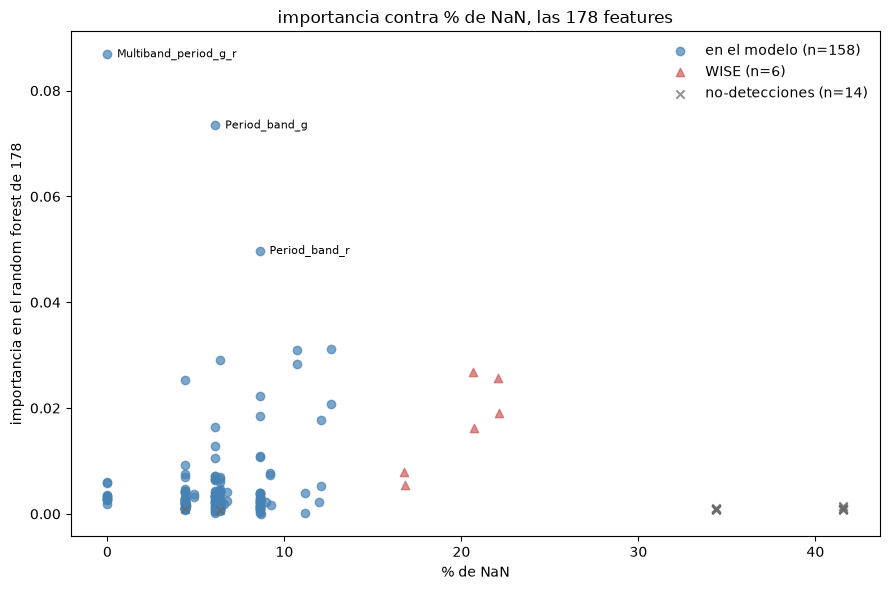

In [15]:
estilo = {
    "en el modelo": ("steelblue", "o"),
    "WISE": ("indianred", "^"),
    "no-detecciones": ("dimgray", "x"),
}

fig, ax = plt.subplots(figsize=(9, 6))
for bloque, (color, marca) in estilo.items():
    sub = comp[comp["bloque"] == bloque]
    ax.scatter(
        sub["pct_nan"],
        sub["importancia_178"],
        s=36,
        alpha=0.7,
        c=color,
        marker=marca,
        label=f"{bloque} (n={len(sub)})",
    )

# nombre solo a los tres periodos, el resto se lee por bloque
for nombre in ["Multiband_period_g_r", "Period_band_g", "Period_band_r"]:
    ax.annotate(
        nombre,
        (comp.loc[nombre, "pct_nan"], comp.loc[nombre, "importancia_178"]),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )

ax.set_xlabel("% de NaN")
ax.set_ylabel("importancia en el random forest de 178")
ax.set_title("importancia contra % de NaN, las 178 features")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Con las 178 tampoco aparece una relacion: la correlacion de Spearman entre % de NaN e importancia da -0.08. Mas NaN no quiere decir menos importancia, depende del bloque.
\\
Las no-detecciones, que son las que mas NaN tienen (34 a 42%), quedan al fondo: puestos 127 a 169 de 178, y entre las 14 suman 1.4% de la importancia. Descartarlas no cuesta nada.
\\
Los colores WISE son otra cosa. Con 17 a 22% de NaN quedan arriba: g-W2 y r-W2 en los puestos 8 y 9, y las seis suman cerca del 10% de la importancia. El modelo las usa cuando estan, asi que decir que no aportan era mucho. Pero el F1 macro en val no se mueve (0.923 con 158 y 0.924 con 178), o sea no agregan nada que el modelo no sacara ya de las otras. Sacarlas sigue siendo razonable, por otra razon: no mejoran el resultado y obligan a imputar un quinto de los objetos.
\\
Ojo con leer la importancia como lo que el modelo necesita. Se reparte entre features parecidas, y en estas columnas una parte de los valores es la mediana imputada. Ademas la comparacion de F1 es con una sola particion.

## Analisis cualitativo del GMM

Hasta aca medimos el GMM con numeros. Ahora miramos objetos: cuales quedan al centro de cada componente, cuales quedan afuera, cuales quedan entre dos componentes, y si dentro de una clase aparecen grupos. Todo con el GMM de arriba y los objetos de test.

Las curvas de luz salen de `lcs.parquet` y cargamos solo las de test. Hay que limpiarlas: sacamos las detecciones sin corregir (`corrected`), las dudosas (`dubious`) y las que traen magnitud 100, que es un relleno. Para plegar usamos el periodo multibanda, el mismo que entra al modelo.

En todos los graficos verde es la banda g y rojo la banda r. El eje vertical es magnitud, con lo mas brillante arriba.

In [15]:
from ic_project.visualizacion import fase_plegada

lcs = pd.read_parquet(
    ruta_datos / "lcs.parquet",
    columns=["oid", "mjd", "fid", "magpsf_corr", "corrected", "dubious"],
    filters=[("oid", "in", list(conjuntos["oid_test"]))],
)
limpias = lcs[lcs["corrected"] & ~lcs["dubious"] & (lcs["magpsf_corr"] < 30)]
curvas = dict(tuple(limpias.groupby("oid")))

print("detecciones de los objetos de test:", len(lcs))
print("quedan despues de limpiar:", len(limpias))
print("objetos de test sin ninguna deteccion limpia:", len(conjuntos["oid_test"]) - len(curvas))

bandas = {1: "tab:green", 2: "tab:red"}


def dibujar_curva(ax, oid, titulo, periodo=None):
    """Sin periodo dibuja magnitud contra tiempo. Con periodo, la curva plegada en dos ciclos."""
    sub = curvas.get(oid)
    if sub is None:
        ax.text(0.5, 0.5, "sin detecciones limpias", ha="center", va="center", transform=ax.transAxes, fontsize=8)
    else:
        for fid, color in bandas.items():
            b = sub[sub["fid"] == fid]
            mag = b["magpsf_corr"].to_numpy()
            if periodo is None:
                ax.scatter(b["mjd"], mag, s=4, alpha=0.5, c=color, linewidths=0)
            else:
                fase = fase_plegada(b["mjd"].to_numpy(), float(periodo))
                ax.scatter(np.r_[fase, fase + 1], np.tile(mag, 2), s=4, alpha=0.5, c=color, linewidths=0)
        ax.invert_yaxis()
    ax.set_title(titulo, fontsize=8)
    ax.tick_params(labelsize=7)


def mahalanobis2(z, modelo, k):
    """Distancia al centro del componente k, medida con la covarianza de ese componente."""
    d = z - modelo.means_[k]
    return np.einsum("ij,jk,ik->i", d, modelo.precisions_[k], d)


# una fila por objeto de test, con lo que vamos a mirar
crudo = X.set_index(oids).loc[conjuntos["oid_test"]]
cols_g = [c for c in prep.columnas_ if c.endswith("_g")]
cols_r = [c for c in prep.columnas_ if c.endswith("_r") and not c.endswith("_g_r")]
conteo = limpias.groupby(["oid", "fid"]).size().unstack(fill_value=0).reindex(conjuntos["oid_test"], fill_value=0)

obj = pd.DataFrame(
    {
        "oid": conjuntos["oid_test"].to_numpy(),
        "clase": clases_test,
        "componente": pred_gmm,
        "loglik": gmm.score_samples(z_test).astype(float),
        "periodo": conjuntos["periodo_test"].to_numpy(),
        "n_g": conteo[1].to_numpy(),
        "n_r": conteo[2].to_numpy(),
        "detecciones": (conteo[1] + conteo[2]).to_numpy(),
        "amplitud_g": crudo["Amplitude_g"].to_numpy(),
        "color_g_r": crudo["g-r_mean_g_r"].to_numpy(),
        "sin_una_banda": (crudo[cols_g].isna().all(axis=1) | crudo[cols_r].isna().all(axis=1)).to_numpy(),
    }
)

# periodo sospechoso: la frecuencia cae a menos de 0.01 de un numero entero de ciclos por dia.
# es el alias tipico de observar una vez por noche (periodos de 1, 1/2, 1/3 de dia)
frecuencia = 1 / obj["periodo"]
obj["periodo_alias"] = (frecuencia.round() >= 1) & ((frecuencia - frecuencia.round()).abs() < 0.01)

print()
print("periodo en un alias de 1 dia, por clase")
print(obj.groupby("clase")["periodo_alias"].mean().round(3))

detecciones de los objetos de test: 750509
quedan despues de limpiar: 739571
objetos de test sin ninguna deteccion limpia: 4

periodo en un alias de 1 dia, por clase
clase
CEP     0.017
DSCT    0.050
EB      0.030
LPV     0.301
RRL     0.030
Name: periodo_alias, dtype: float64


### Prototipos

Los tres objetos mas cercanos al centro de cada componente, entre los que el GMM asigna a ese componente. La cercania es la distancia de Mahalanobis, que usa la covarianza del componente y es la misma que usa el GMM por dentro.

,n,clase_mas_comun,periodo_mediano,amplitud_g_mediana,detecciones_medianas,periodo_alias,sin_una_banda
componente,,,,,,,
0,74,LPV,65.293,0.429,627.5,0.284,0.432
1,314,EB,0.474,0.365,430.5,0.035,0.210
2,129,LPV,107.955,1.346,614.0,0.271,0.085
3,198,EB,0.365,0.317,114.5,0.056,0.116
4,548,RRL,0.350,0.328,582.5,0.027,0.026


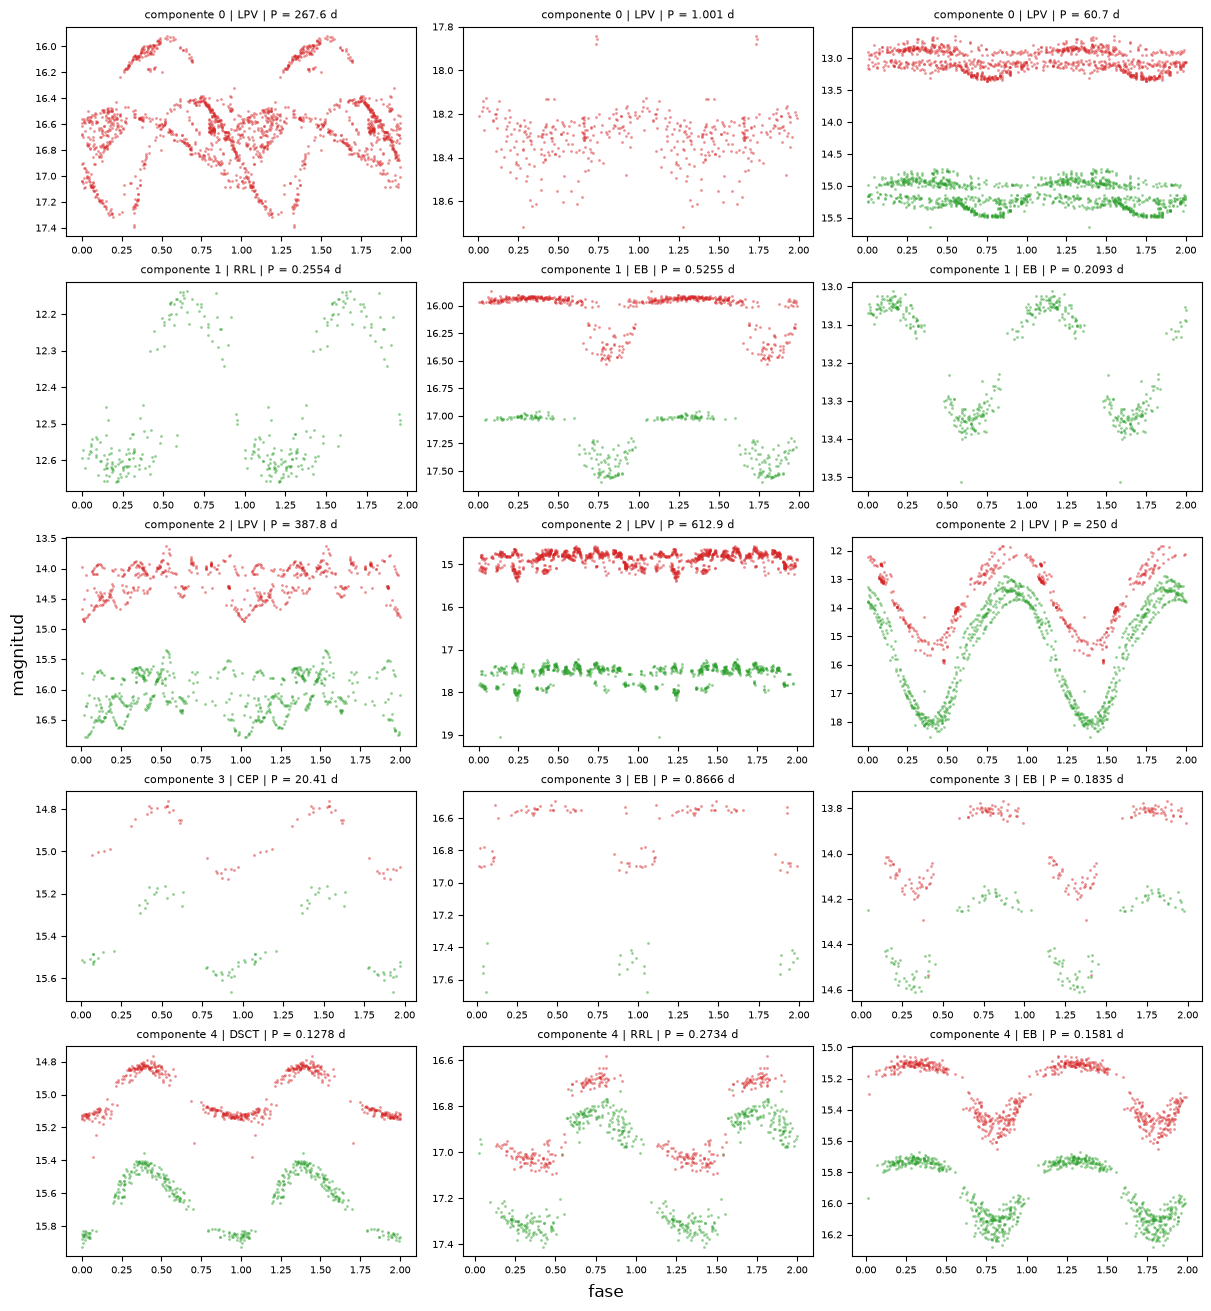

In [16]:
resumen = obj.groupby("componente").agg(
    n=("oid", "size"),
    clase_mas_comun=("clase", lambda s: s.mode()[0]),
    periodo_mediano=("periodo", "median"),
    amplitud_g_mediana=("amplitud_g", "median"),
    detecciones_medianas=("detecciones", "median"),
    periodo_alias=("periodo_alias", "mean"),
    sin_una_banda=("sin_una_banda", "mean"),
)
display(resumen.round(3))

fig, axes = plt.subplots(gmm.n_components, 3, figsize=(12, 13), layout="constrained")
for k in range(gmm.n_components):
    del_k = np.flatnonzero(pred_gmm == k)
    cerca = del_k[np.argsort(mahalanobis2(z_test[del_k], gmm, k))[:3]]
    for ax, i in zip(axes[k], cerca):
        fila = obj.iloc[i]
        dibujar_curva(
            ax,
            fila["oid"],
            f"componente {k} | {fila['clase']} | P = {fila['periodo']:.4g} d",
            periodo=fila["periodo"],
        )
fig.supxlabel("fase")
fig.supylabel("magnitud")
plt.show()

Los componentes no se ordenan solo por clase, tambien por como esta observado el objeto. Se ve en la tabla:

- **Componente 4** (548 objetos): periodo corto y bien observado. Mediana de unas 580 detecciones y casi ninguno sin una banda. Sus prototipos son una DSCT, una RRL y una EB con periodos de 0.13 a 0.27 dias. Para el GMM son lo mismo, aunque sean tres clases.
- **Componente 3** (198): los mal muestreados. Mediana de 114 detecciones, contra 430 a 630 en el resto, y se nota en los prototipos, que tienen pocos puntos.
- **Componente 1** (314): periodo corto, pero a uno de cada cinco le falta una banda, como a la RRL prototipo, que solo tiene banda g.
- **Componentes 0 y 2**: las LPV. El 2 junta las de amplitud grande (mediana de 1.3 magnitudes en g) y periodo largo. El 0 junta las de amplitud chica, y al 43% le falta una banda.

### Outliers

Los 8 objetos de test con menor verosimilitud en el GMM. A la izquierda la curva en el tiempo y a la derecha plegada.


,oid,clase,componente,loglik,periodo,n_g,n_r,periodo_alias,sin_una_banda
0,ZTF18abskwur,CEP,2,-22.7,18.7747,30,14,False,False
1,ZTF18abfxrti,LPV,2,-22.6,1.0007,3,14,True,False
2,ZTF18abcqewa,LPV,2,-22.5,351.8518,22,906,False,False
3,ZTF18aborpmv,LPV,2,-22.2,487.1795,567,22,False,False
4,ZTF18aaxddqq,LPV,2,-22.1,0.9940,104,169,True,False
5,ZTF18aaywfxv,LPV,2,-22.1,0.9987,1408,1177,True,False
6,ZTF18abchpxl,LPV,2,-21.6,157.0248,0,0,False,False
7,ZTF18abcklqk,LPV,2,-21.3,0.4996,562,404,True,False


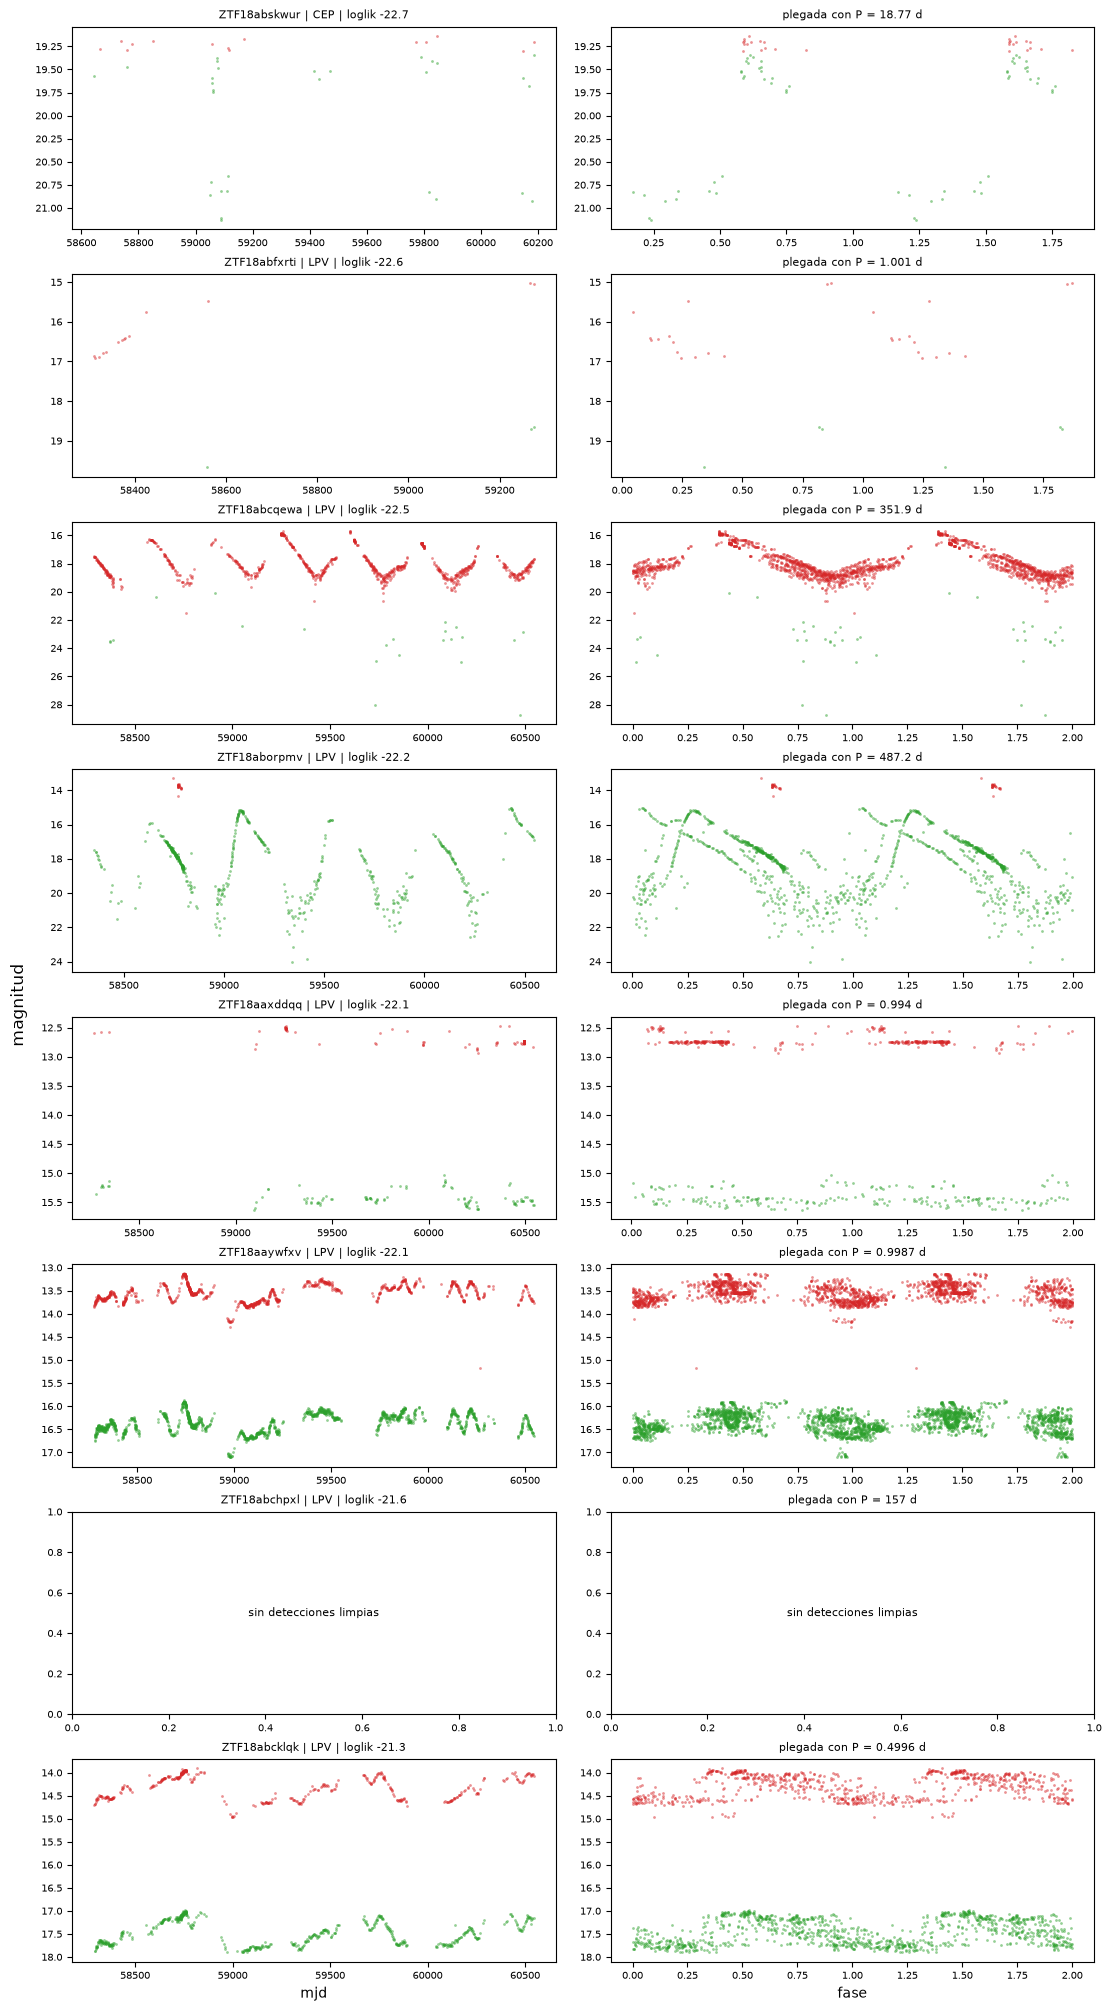

In [17]:
raros = obj.sort_values("loglik").head(8)
display(
    raros[["oid", "clase", "componente", "loglik", "periodo", "n_g", "n_r", "periodo_alias", "sin_una_banda"]]
    .round({"loglik": 1, "periodo": 4})
    .reset_index(drop=True)
)

fig, axes = plt.subplots(len(raros), 2, figsize=(11, 20), layout="constrained")
for (ax_t, ax_p), (_, fila) in zip(axes, raros.iterrows()):
    dibujar_curva(ax_t, fila["oid"], f"{fila['oid']} | {fila['clase']} | loglik {fila['loglik']:.1f}")
    dibujar_curva(ax_p, fila["oid"], f"plegada con P = {fila['periodo']:.4g} d", periodo=fila["periodo"])
axes[-1, 0].set_xlabel("mjd")
axes[-1, 1].set_xlabel("fase")
fig.supylabel("magnitud")
plt.show()

In [18]:
# mas alla de los 8 de arriba: el 5% con menor verosimilitud contra el resto
obj["outlier"] = obj["loglik"] <= obj["loglik"].quantile(0.05)
print("outliers:", int(obj["outlier"].sum()), "de", len(obj))
print()

print("fraccion de cada clase que cae en ese 5%")
print(obj.groupby("clase")["outlier"].mean().round(3))
print()

display(
    obj.groupby("outlier")
    .agg(
        n=("oid", "size"),
        periodo_alias=("periodo_alias", "mean"),
        sin_una_banda=("sin_una_banda", "mean"),
        menos_de_30_detecciones=("detecciones", lambda s: (s < 30).mean()),
        amplitud_g_mediana=("amplitud_g", "median"),
    )
    .round(3)
)

outliers: 64 de 1263

fraccion de cada clase que cae en ese 5%
clase
CEP     0.017
DSCT    0.012
EB      0.022
LPV     0.243
RRL     0.003
Name: outlier, dtype: float64



,n,periodo_alias,sin_una_banda,menos_de_30_detecciones,amplitud_g_mediana
outlier,,,,,
False,1199,0.061,0.112,0.030,0.353
True,64,0.312,0.188,0.047,0.869


Siete de los ocho son LPV y los ocho caen en el componente 2.

En el 5% con menor verosimilitud cae el 24% de las LPV y menos del 2.5% de las demas clases. El 31% tiene el periodo en un alias de 1 dia, contra 6% en el resto, y la amplitud mediana es mas del doble.

### Entre dos componentes

Objetos a los que el GMM les da probabilidades parecidas en dos componentes. Tomamos los que tienen al menos 0.3 en el segundo componente mas probable.


objetos con el componente mas probable sobre 0.9: 62.1%
objetos entre dos componentes: 160 (12.7%)

clase contra par de componentes


par,0 y 1,0 y 2,0 y 3,1 y 2,1 y 3,1 y 4,2 y 3,total
clase,,,,,,,,
CEP,0,1,0,1,5,18,3,28
DSCT,0,0,0,0,5,6,0,11
EB,0,0,1,4,9,54,7,75
LPV,1,8,1,0,1,0,4,15
RRL,0,0,0,0,10,21,0,31
total,1,9,2,5,30,99,14,160


fraccion de cada clase que queda entre dos componentes
clase
CEP     0.159
DSCT    0.138
EB      0.186
LPV     0.073
RRL     0.078
Name: entre_dos, dtype: float64


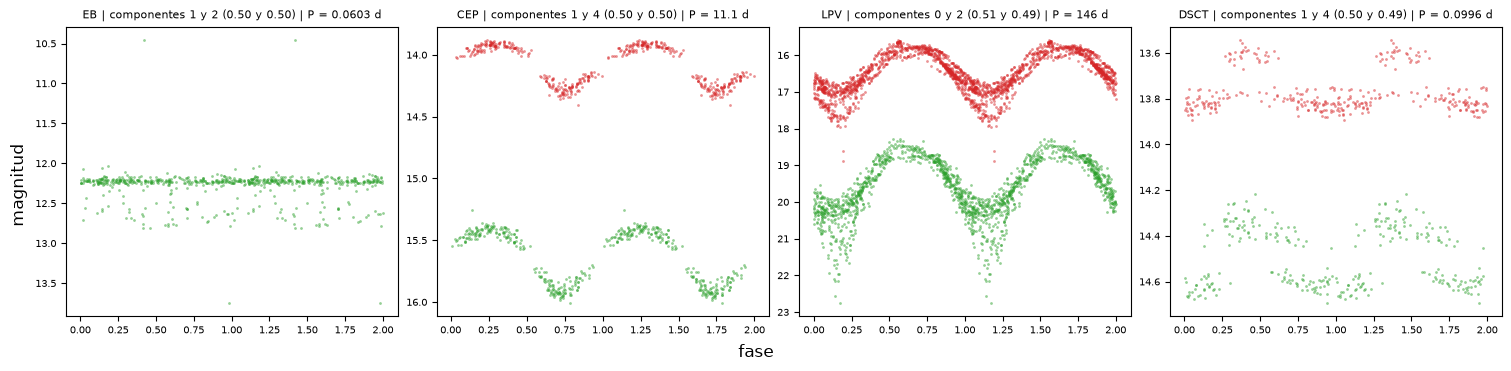

In [19]:
proba = gmm.predict_proba(z_test)
orden = np.argsort(proba, axis=1)[:, ::-1]
obj["p1"] = np.take_along_axis(proba, orden[:, :1], axis=1).ravel()
obj["p2"] = np.take_along_axis(proba, orden[:, 1:2], axis=1).ravel()
obj["par"] = [f"{min(a, b)} y {max(a, b)}" for a, b in orden[:, :2]]

# entre dos componentes: el segundo mas probable se lleva al menos 0.3
obj["entre_dos"] = obj["p2"] >= 0.3
dudosos = obj[obj["entre_dos"]]

print("objetos con el componente mas probable sobre 0.9:", f"{(obj['p1'] > 0.9).mean():.1%}")
print("objetos entre dos componentes:", len(dudosos), f"({obj['entre_dos'].mean():.1%})")
print()

print("clase contra par de componentes")
display(pd.crosstab(dudosos["clase"], dudosos["par"], margins=True, margins_name="total"))

print("fraccion de cada clase que queda entre dos componentes")
print(obj.groupby("clase")["entre_dos"].mean().round(3))

# los cuatro mas repartidos
mas_dudosos = dudosos.sort_values("p2", ascending=False).head(4)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), layout="constrained")
for ax, (_, fila) in zip(axes, mas_dudosos.iterrows()):
    dibujar_curva(
        ax,
        fila["oid"],
        f"{fila['clase']} | componentes {fila['par']} ({fila['p1']:.2f} y {fila['p2']:.2f}) | P = {fila['periodo']:.3g} d",
        periodo=fila["periodo"],
    )
fig.supxlabel("fase")
fig.supylabel("magnitud")
plt.show()

El 62% de los objetos tiene un componente claro (probabilidad sobre 0.9). 160 quedan entre dos, el 12.7%.

Casi todos estan entre los componentes 1, 3 y 4: 99 entre el 1 y el 4, y 30 entre el 1 y el 3. Esos tres componentes comparten las mismas clases (EB, RRL, CEP y DSCT), asi que la duda no es entre una clase y otra. Es entre grupos que el GMM corto dentro de la misma nube de periodo corto. Por eso las mas afectadas son EB (19%), CEP (16%) y DSCT (14%).

Las LPV dudan poco (7%) y cuando dudan es sobre todo entre el 0 y el 2, que son los dos de LPV.

### Sub-clusters dentro de cada clase

Para cada clase ajustamos un GMM solo con los objetos de esa clase en train, probando de 1 a 6 componentes, y nos quedamos con el de menor BIC. Despues asignamos los objetos de test. El ultimo grafico muestra el objeto mas central de cada sub-cluster.


In [20]:
y_train = conjuntos["y_train"].to_numpy()

sub_gmm = {}
bic = {}
obj["sub"] = -1
for clase in colores:
    z_clase = z_train[y_train == clase]
    candidatos = {
        k: GaussianMixture(n_components=k, covariance_type="full", random_state=42, n_init=5).fit(z_clase)
        for k in range(1, 7)
    }
    bic[clase] = {k: m.bic(z_clase) for k, m in candidatos.items()}
    sub_gmm[clase] = candidatos[min(bic[clase], key=bic[clase].get)]
    de_la_clase = clases_test == clase
    obj.loc[de_la_clase, "sub"] = sub_gmm[clase].predict(z_test[de_la_clase])

print("BIC por numero de componentes (mas bajo es mejor)")
display(pd.DataFrame(bic).T.round(0).astype(int))
print("componentes elegidos:", {clase: m.n_components for clase, m in sub_gmm.items()})
print()

display(
    obj.groupby(["clase", "sub"])
    .agg(
        n=("oid", "size"),
        periodo_mediano=("periodo", "median"),
        amplitud_g_mediana=("amplitud_g", "median"),
        color_g_r_mediano=("color_g_r", "median"),
        periodo_alias=("periodo_alias", "mean"),
        sin_una_banda=("sin_una_banda", "mean"),
    )
    .round(3)
)

BIC por numero de componentes (mas bajo es mejor)


,1,2,3,4,5,6
CEP,18223,16747,16396,16388,16475,16603
DSCT,7278,6616,6717,6847,6816,7108
EB,43053,38509,38092,37869,37764,37995
LPV,28637,27927,27451,27033,26856,26961
RRL,35873,32577,32467,32435,32473,32360


componentes elegidos: {'CEP': 4, 'DSCT': 2, 'EB': 5, 'LPV': 5, 'RRL': 6}



n  periodo_mediano  amplitud_g_mediana  color_g_r_mediano  \
clase sub                                                                
CEP   0     47            1.644               0.431              0.833   
      1     45            1.313               0.393              1.191   
      2     66            3.158               0.328              1.319   
      3     18            4.566               0.371              0.131   
DSCT  0     55            0.081               0.291             -0.091   
      1     25            0.100               0.225             -0.112   
EB    0     56            0.557               0.744              0.673   
      1    121            0.367               0.339              0.690   
      2     35            0.432               0.363              0.516   
      3     37            0.175               0.166              0.523   
      4    154            0.187               0.291              0.669   
LPV   0     42           63.658                 NaN              2.543   
      1     43            1.000               0.384              2.238   
      2     19            1.000               0.383                NaN   
      3     58          255.137               2.482              1.700   
      4     44           49.101               0.404              2.386   
RRL   0     50            0.502               0.519             -0.079   
      1     74            0.370               0.329             -0.019   
      2    109            0.547               0.609              0.036   
      3     26            0.276               0.324              0.043   
      4     31            0.366               0.392              0.083   
      5    108            0.322               0.287             -0.092   

           periodo_alias  sin_una_banda  
clase sub                                
CEP   0            0.000          0.149  
      1            0.067          0.133  
      2            0.000          0.076  
      3            0.000          0.889  
DSCT  0            0.036          0.036  
      1            0.080          0.120  
EB    0            0.018          0.036  
      1            0.008          0.149  
      2            0.000          0.000  
      3            0.081          0.081  
      4            0.045          0.013  
LPV   0            0.310          0.857  
      1            0.535          0.116  
      2            0.368          1.000  
      3            0.121          0.017  
      4            0.273          0.023  
RRL   0            0.040          0.180  
      1            0.027          0.014  
      2            0.028          0.009  
      3            0.038          0.308  
      4            0.065          0.032  
      5            0.019          0.000

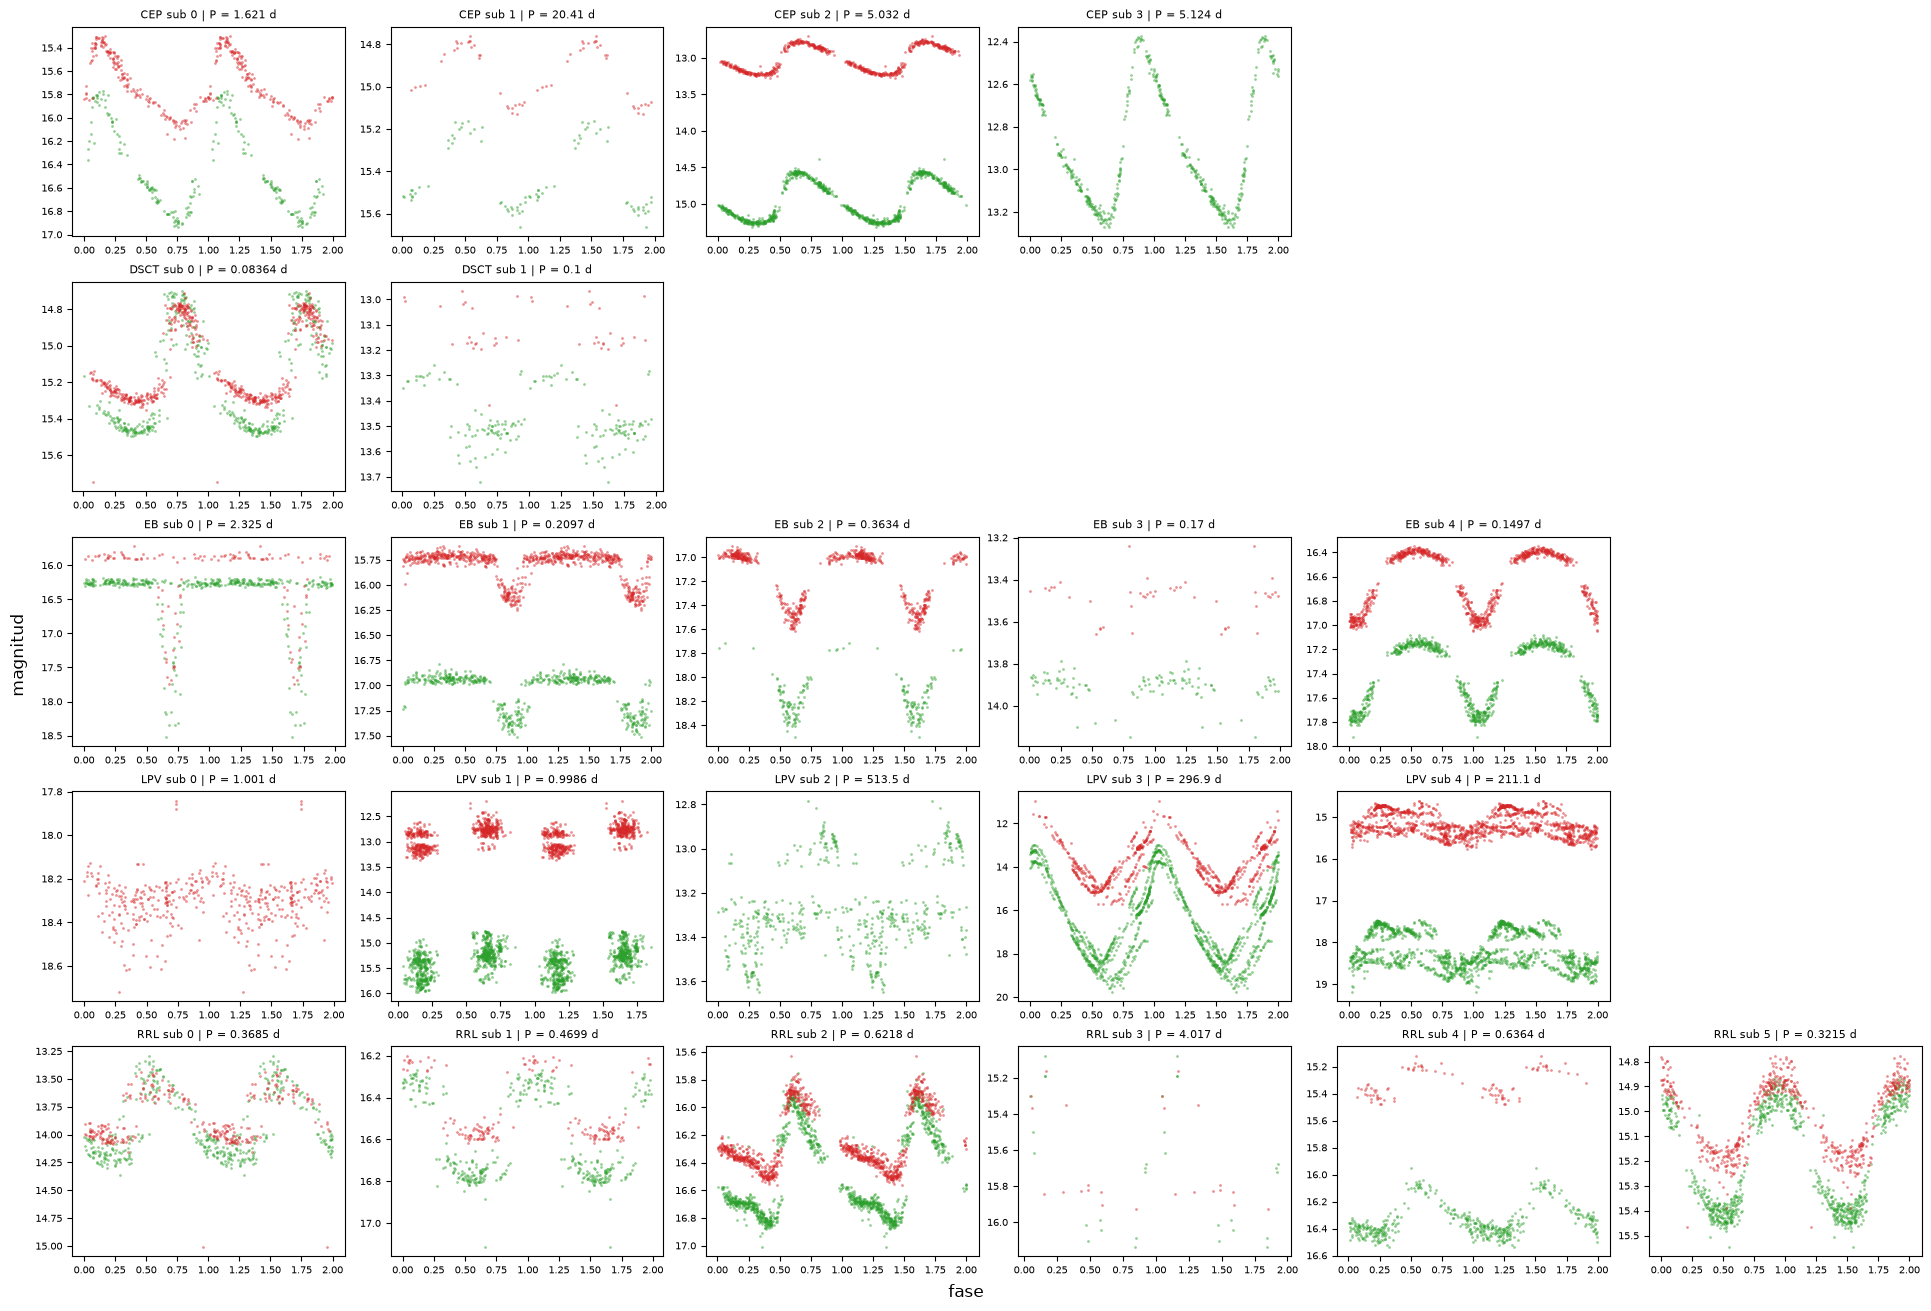

In [21]:
# el objeto mas central de cada sub-cluster, una fila por clase
n_cols = max(m.n_components for m in sub_gmm.values())
fig, axes = plt.subplots(len(sub_gmm), n_cols, figsize=(3.2 * n_cols, 13), layout="constrained")
for fila_ax, (clase, modelo) in zip(axes, sub_gmm.items()):
    for k, ax in enumerate(fila_ax):
        idx = np.flatnonzero((clases_test == clase) & (obj["sub"] == k).to_numpy())
        if len(idx) == 0:
            ax.axis("off")
            continue
        fila = obj.iloc[idx[np.argmin(mahalanobis2(z_test[idx], modelo, k))]]
        dibujar_curva(ax, fila["oid"], f"{clase} sub {k} | P = {fila['periodo']:.4g} d", periodo=fila["periodo"])
fig.supxlabel("fase")
fig.supylabel("magnitud")
plt.show()

El BIC pide entre 2 y 6 sub-clusters segun la clase. En RRL elige 6, que es el maximo que probamos, y casi no cambia desde 2, asi que el numero exacto no hay que tomarlo muy en serio.

- En LPV, a casi todos los objetos de los sub 0 y 2 les falta una banda, y en el sub 1 mas de la mitad tiene el periodo en un alias de 1 dia.
- En CEP, al 89% del sub 3 le falta una banda. En RRL, al 31% del sub 3.

### Pendiente

Repetir este analisis con MCDSVDD (distancia al centro en vez de verosimilitud), y el experimento de sacar una clase del entrenamiento para ver si el modelo la marca como rara.
